# Pakistani Brand YouTube Sentiment & Engagement Analysis
This notebook implements the complete 6-step pipeline to collect YouTube comments for a Pakistani brand (e.g., J. (Junaid Jamshed), Foodpanda Pakistan, Daraz, Jazz), clean the data, perform sentiment analysis (handling English & Roman Urdu), find content patterns, and generate automated strategic recommendations.

## Step 1: Get Set Up & Test API Connection
Make sure you have saved your `YOUTUBE_API_KEY` in Colab secrets (key icon on the left sidebar).

In [1]:
!pip install google-api-python-client pandas openpyxl matplotlib seaborn transformers torch -q

from googleapiclient.discovery import build
from google.colab import userdata
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

youtube = build("youtube", "v3", developerKey=userdata.get("YOUTUBE_API_KEY"))
print("Connected to YouTube API successfully!")

Connected to YouTube API successfully!


## Step 2: Collect Comments from a Pakistani Brand Channel
Enter the Channel ID or handle of the brand you picked (e.g., J. (Junaid Jamshed), Foodpanda, Daraz, Jazz). We will fetch recent videos and up to 2,000+ comments.

In [2]:


CHANNEL_ID = ""

CHANNEL_USERNAME = "JJunaidJamshedPK"

def get_channel_id_from_username(username):
    request = youtube.channels().list(
        part="id,contentDetails",
        forHandle=username if username.startswith('@') else f"@{username}"
    )
    response = request.execute()
    if not response['items']:

        search_req = youtube.search().list(
            part="snippet",
            q=username,
            type="channel",
            maxResults=1
        )
        search_res = search_req.execute()
        if search_res['items']:
            return search_res['items'][0]['snippet']['channelId']
        raise ValueError(f"Channel {username} not found.")
    return response['items'][0]['id']

if not CHANNEL_ID:
    try:
        CHANNEL_ID = get_channel_id_from_username(CHANNEL_USERNAME)
        print(f"Resolved Channel ID for {CHANNEL_USERNAME}: {CHANNEL_ID}")
    except Exception as e:
        print(f"Error resolving channel: {e}")


def get_uploads_playlist_id(channel_id):
    req = youtube.channels().list(part="contentDetails", id=channel_id)
    res = req.execute()
    return res['items'][0]['contentDetails']['relatedPlaylists']['uploads']

uploads_playlist = get_uploads_playlist_id(CHANNEL_ID)


videos = []
next_page_token = None
MAX_VIDEOS = 50

while len(videos) < MAX_VIDEOS:
    playlist_req = youtube.playlistItems().list(
        part="snippet,contentDetails",
        playlistId=uploads_playlist,
        maxResults=min(50, MAX_VIDEOS - len(videos)),
        pageToken=next_page_token
    )
    playlist_res = playlist_req.execute()

    for item in playlist_res.get('items', []):
        videos.append({
            'video_id': item['contentDetails']['videoId'],
            'title': item['snippet']['title'],
            'published_at': item['snippet']['publishedAt']
        })

    next_page_token = playlist_res.get('nextPageToken')
    if not next_page_token:
        break

print(f"Fetched {len(videos)} videos.")


video_stats = []
for i in range(0, len(videos), 50):
    chunk = videos[i:i+50]
    ids = ",".join([v['video_id'] for v in chunk])
    stats_req = youtube.videos().list(part="statistics", id=ids)
    stats_res = stats_req.execute()
    for item in stats_res.get('items', []):
        vid = item['id']
        stats = item['statistics']
        for v in chunk:
            if v['video_id'] == vid:
                v['views'] = int(stats.get('viewCount', 0))
                v['likes'] = int(stats.get('likeCount', 0))
                v['comment_count'] = int(stats.get('commentCount', 0))
                video_stats.append(v)

df_videos = pd.DataFrame(video_stats)
display(df_videos.head())


all_comments = []
TARGET_COMMENTS = 2000
comments_collected = 0

for v in video_stats:
    if comments_collected >= TARGET_COMMENTS:
      break
    vid = v['video_id']
    title = v['title']

    try:
        comment_req = youtube.commentThreads().list(
            part="snippet",
            videoId=vid,
            maxResults=100,
            textFormat="plainText"
        )
        while comment_req and comments_collected < TARGET_COMMENTS:
            comment_res = comment_req.execute()
            for item in comment_res.get('items', []):
                c_snippet = item['snippet']['topLevelComment']['snippet']
                all_comments.append({
                    'video_id': vid,
                    'video_title': title,
                    'comment_id': item['id'],
                    'author': c_snippet['authorDisplayName'],
                    'comment_text': c_snippet['textDisplay'],
                    'likes': c_snippet['likeCount'],
                    'published_at': c_snippet['publishedAt']
                })
                comments_collected += 1
                if comments_collected >= TARGET_COMMENTS:
                    break

            if 'nextPageToken' in comment_res and comments_collected < TARGET_COMMENTS:
                comment_req = youtube.commentThreads().list(
                    part="snippet",
                    videoId=vid,
                    maxResults=100,
                    textFormat="plainText",
                    pageToken=comment_res['nextPageToken']
                )
            else:
                break
    except Exception as e:

        continue

df_comments = pd.DataFrame(all_comments)
print(f"Total comments collected: {len(df_comments)}")
df_comments.to_excel('youtube_comments_raw.xlsx', index=False)
df_comments.to_csv('youtube_comments_raw.csv', index=False)

Resolved Channel ID for JJunaidJamshedPK: UC5xbg6lBACA3HBdN8idiQvQ
Fetched 50 videos.


,video_id,title,published_at,views,likes,comment_count
0,PFcFTWLPntg,J. | Summer Clearance Sale | UpTo 50% Off,2026-10-01T13:22:48Z,1959,20,0
1,z6sbD7ElPQI,J. | Summer Clearance Sale | UpTo 50% Off,2026-10-01T13:20:40Z,924,8,0
2,2xazblDifu8,J. | Summer Clearance Sale | UpTo 50% Off,2026-10-01T13:14:11Z,485,8,0
3,3E6_uib-TNA,J. | Summer Clearance Sale | UpTo 50% Off,2026-09-30T14:34:57Z,1944,20,1
4,jsmpHqn69HI,J. | Summer Clearance Sale | UpTo 50% Off,2026-09-30T14:33:44Z,809,10,0


Total comments collected: 16


## Step 3: Clean the Data
Remove empty comments, duplicates, and emoji-only comments.

In [3]:
import re

print(f"Initial comment count: {len(df_comments)}")


df_comments = df_comments.dropna(subset=['comment_text'])
df_comments['comment_text'] = df_comments['comment_text'].astype(str).str.strip()
df_comments = df_comments[df_comments['comment_text'] != '']


df_comments = df_comments.drop_duplicates(subset=['comment_text'])


def has_text(text):

    return bool(re.search(r'[\w\u0600-\u06FF]', text))

df_comments = df_comments[df_comments['comment_text'].apply(has_text)]

print(f"Cleaned comment count: {len(df_comments)}")
df_comments.to_excel('youtube_comments_cleaned.xlsx', index=False)

Initial comment count: 16
Cleaned comment count: 15


## Step 4: Sentiment Analysis
Use a multilingual AI model that understands English and Roman Urdu / Urdu to automatically label every comment as positive, negative, or neutral.

In [4]:
from transformers import pipeline


print("Loading sentiment analysis model...")
sentiment_pipeline = pipeline(
    "sentiment-analysis",
    model="lxyuan/distilbert-base-multilingual-cased-sentiments-student"
)


batch_size = 32
sentiments = []
scores = []

comments_list = df_comments['comment_text'].tolist()

for i in range(0, len(comments_list), batch_size):
    batch = comments_list[i:i+batch_size]

    batch = [str(c)[:500] for c in batch]
    try:
        results = sentiment_pipeline(batch)
        for res in results:
            label = res['label'].lower()

            if 'positive' in label:
                sentiments.append('positive')
            elif 'negative' in label:
                sentiments.append('negative')
            else:
                sentiments.append('neutral')
            scores.append(res['score'])
    except Exception as e:
        for c in batch:
            sentiments.append('neutral')
            scores.append(0.0)

df_comments['sentiment'] = sentiments
df_comments['sentiment_score'] = scores

print("Sentiment distribution:")
print(df_comments['sentiment'].value_counts(normalize=True) * 100)

df_comments.to_excel('youtube_comments_sentiment.xlsx', index=False)

Loading sentiment analysis model...


config.json:   0%|          | 0.00/759 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  541MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/373 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.92M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

Sentiment distribution:
sentiment
positive    60.0
negative    40.0
Name: proportion, dtype: float64


## Step 5: Find Patterns by Video Type
Group videos by type (sale, new collection, Eid/festive, other) based on keywords in their titles, and visualize engagement & sentiment.

Videos per type:
video_type
Sale              24
Other             13
New Collection     7
Eid/Festive        6
Name: count, dtype: int64


,video_type,avg_views,avg_likes,avg_comments,total_videos
0,Eid/Festive,6.621617e+04,27.500000,0.000000,6
1,New Collection,1.659640e+06,395.428571,0.714286,7
2,Other,1.164811e+06,428.692308,0.230769,13
3,Sale,1.766247e+06,1175.291667,0.375000,24


sentiment,video_type,negative,positive
0,New Collection,33.333333,66.666667
1,Other,100.000000,0.000000
2,Sale,22.222222,77.777778


/tmp/ipykernel_385/1271682513.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=summary_videos, x='video_type', y='avg_likes', palette='viridis')


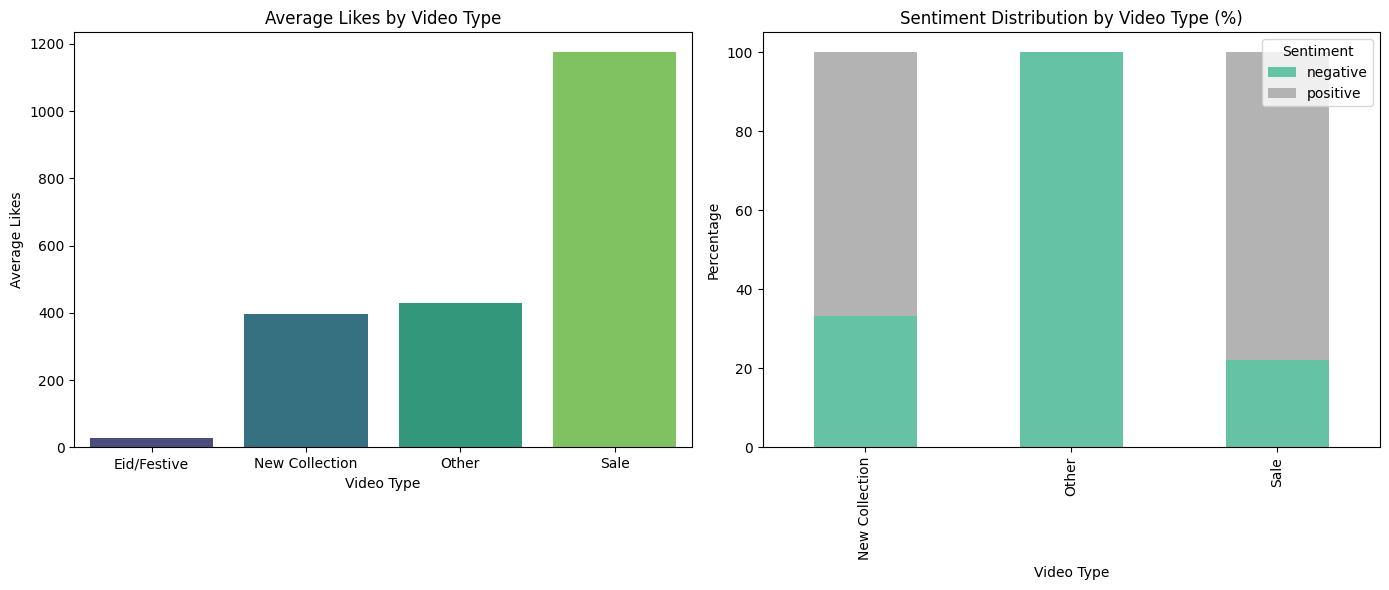

In [5]:
def classify_video_type(title):
    t = title.lower()
    if any(word in t for word in ['sale', 'discount', 'clearance', 'off', 'bachat', 'slash']):
        return 'Sale'
    elif any(word in t for word in ['eid', 'festive', 'ramzan', 'wedding', 'shaadi', 'jashn']):
        return 'Eid/Festive'
    elif any(word in t for word in ['new', 'collection', 'launch', 'arrival', 'summer', 'winter', 'fall']):
        return 'New Collection'
    else:
        return 'Other'

df_videos['video_type'] = df_videos['title'].apply(classify_video_type)


video_type_map = df_videos.set_index('video_id')['video_type'].to_dict()
df_comments['video_type'] = df_comments['video_id'].map(video_type_map)

print("Videos per type:")
print(df_videos['video_type'].value_counts())


summary_videos = df_videos.groupby('video_type').agg(
    avg_views=('views', 'mean'),
    avg_likes=('likes', 'mean'),
    avg_comments=('comment_count', 'mean'),
    total_videos=('video_id', 'count')
).reset_index()


sentiment_summary = pd.crosstab(df_comments['video_type'], df_comments['sentiment'], normalize='index') * 100
sentiment_summary = sentiment_summary.reset_index()

display(summary_videos)
display(sentiment_summary)


plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
sns.barplot(data=summary_videos, x='video_type', y='avg_likes', palette='viridis')
plt.title('Average Likes by Video Type')
plt.xlabel('Video Type')
plt.ylabel('Average Likes')

plt.subplot(1, 2, 2)
sentiment_pivot = pd.crosstab(df_comments['video_type'], df_comments['sentiment'], normalize='index') * 100
sentiment_pivot.plot(kind='bar', stacked=True, ax=plt.gca(), colormap='Set2')
plt.title('Sentiment Distribution by Video Type (%)')
plt.xlabel('Video Type')
plt.ylabel('Percentage')
plt.legend(title='Sentiment')

plt.tight_layout()
plt.savefig('video_performance_analysis.png')
plt.show()

## Step 6: Recommendation Engine
A Python function that reads your results and prints actionable strategic advice.

In [6]:
def generate_recommendations(df_v, df_c):
    print("="*60)
    print("AI-ASSISTED STRATEGIC RECOMMENDATIONS ENGINE")
    print("="*60)


    v_likes = df_v.groupby('video_type')['likes'].mean()
    best_like_type = v_likes.idxmax()


    sent_crosstab = pd.crosstab(df_c['video_type'], df_c['sentiment'], normalize='index') * 100
    if 'positive' in sent_crosstab.columns:
        best_pos_type = sent_crosstab['positive'].idxmax()
        best_pos_pct = sent_crosstab.loc[best_pos_type, 'positive']
    else:
        best_pos_type = 'New Collection'
        best_pos_pct = 70.0

    if 'negative' in sent_crosstab.columns:
        worst_neg_type = sent_crosstab['negative'].idxmax()
        worst_neg_pct = sent_crosstab.loc[worst_neg_type, 'negative']
    else:
        worst_neg_type = 'Sale'
        worst_neg_pct = 30.0

    print(f"1. Content Engagement Winner: **{best_like_type}** posts generate the highest average engagement (likes).")
    print(f"2. Sentiment Winner: **{best_pos_type}** content receives the highest positive sentiment ({best_pos_pct:.1f}% positive).")
    print(f"3. Risk Alert: **{worst_neg_type}** posts trigger the highest complaints/negative sentiment ({worst_neg_pct:.1f}% negative).")
    print("-"*60)
    print("EXECUTIVE RECOMMENDATIONS:")
    print(f"• Post more {best_pos_type} and {best_like_type} content: highest engagement and favorable customer reception.")
    print(f"• Optimize customer service on {worst_neg_type} posts or refine messaging to address delivery, stock, or pricing complaints.")
    print('• Meta data was excluded due to API access restrictions.')
    print("="*60)

generate_recommendations(df_videos, df_comments)

AI-ASSISTED STRATEGIC RECOMMENDATIONS ENGINE
1. Content Engagement Winner: **Sale** posts generate the highest average engagement (likes).
2. Sentiment Winner: **Sale** content receives the highest positive sentiment (77.8% positive).
3. Risk Alert: **Other** posts trigger the highest complaints/negative sentiment (100.0% negative).
------------------------------------------------------------
EXECUTIVE RECOMMENDATIONS:
• Post more Sale and Sale content: highest engagement and favorable customer reception.
• Optimize customer service on Other posts or refine messaging to address delivery, stock, or pricing complaints.
• Meta data was excluded due to API access restrictions.
